# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'gracelh4'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

266 epochs over 965 days; median quoted error 0.041 mag; rms of the light curve 0.175 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


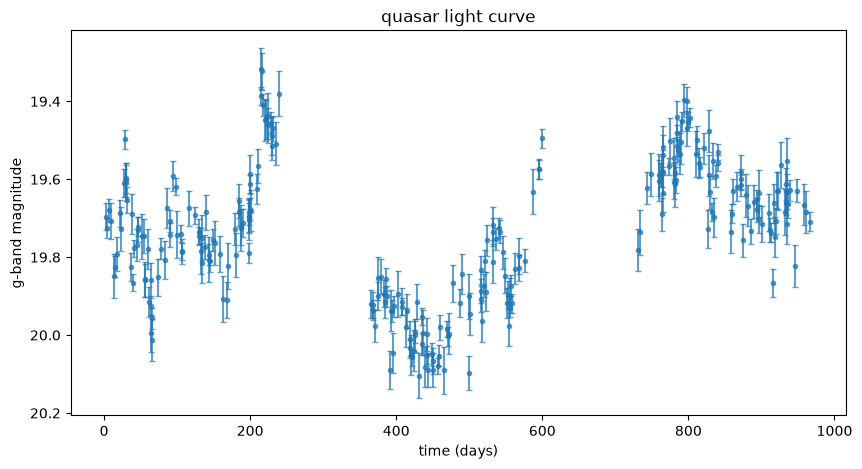

In [8]:
plt.figure(figsize=(10, 5))
plt.errorbar(t, y, yerr=e, fmt='.', capsize=2, alpha=0.7)
plt.xlabel('time (days)')
plt.ylabel('g-band magnitude')
plt.title('quasar light curve')

plt.gca().invert_yaxis()
plt.show()

Highest peak period: 482.28 days
Peak power: 0.3782
False-alarm probability: 3.535e-25


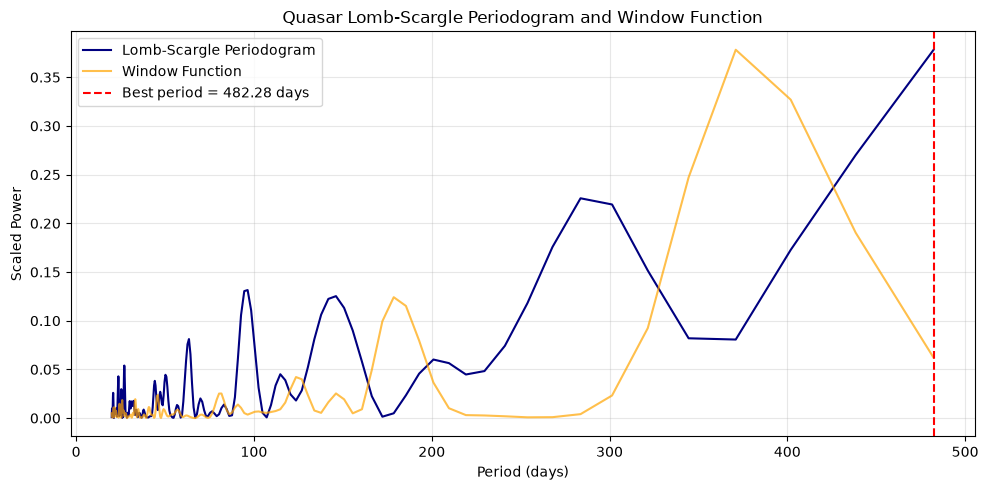

In [9]:
min_period = 20
max_period = T / 2

min_freq = 1 / max_period
max_freq = 1 / min_period

df = 1 / (5 * T)
frequency = np.arange(min_freq, max_freq + df/2, df)

ls = LombScargle(t, y, e)
power = ls.power(frequency)

peak_index = np.argmax(power)
best_frequency = frequency[peak_index]
best_period = 1 / best_frequency
peak_power = power[peak_index]

fap = ls.false_alarm_probability(peak_power, method='baluev', minimum_frequency=min_freq, maximum_frequency=max_freq)

print(f"Highest peak period: {best_period:.2f} days")
print(f"Peak power: {peak_power:.4f}")
print(f"False-alarm probability: {fap:.6g}")

window_ls = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)
window_power = window_ls.power(frequency)
window_scaled = window_power / np.max(window_power) * np.max(power)

plt.figure(figsize=(10, 5))
plt.plot(1 / frequency, power,color='navy',label='Lomb-Scargle Periodogram')
plt.plot(1 / frequency, window_scaled,color='orange',alpha=0.7,label='Window Function')
plt.axvline(best_period,color='red',linestyle='--',label=f'Best period = {best_period:.2f} days')
plt.xlabel('Period (days)')
plt.ylabel('Scaled Power')
plt.title('Quasar Lomb-Scargle Periodogram and Window Function')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**ANSWER (a few sentences):**

The peak around 370 days seems to be an alias of the highest peak. When the period is higher than T/2, it becomes difficult to observe a period. 

It assumes that errors follow a normal distribution, and that the noise at one observation is independent from noise at another. 

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ ___ (+___ / −___) mag, $\tau = $ ___ (+___ / −___) d, $T/\tau = $ ___; the exponential kernel beats the squared exponential by $\Delta\ln L = $ ___; ___ of ___ held-out points are inside the 68% band.


In [10]:
#1
def log_likelihood(theta, t, y, e):
    mu, ln_sigma, ln_tau = theta
    sigma = np.exp(ln_sigma)
    tau = np.exp(ln_tau)
    dt = np.abs(t[:, None] - t[None, :])
    C = sigma**2 * np.exp(-dt / tau)
    C += np.diag(e**2)
    try:
        factor, lower = cho_factor(C, lower=True)
        residual = y - mu
        alpha = cho_solve((factor, lower), residual)
        logdet = 2 * np.sum(np.log(np.diag(factor)))
        N = len(y)
        return -0.5 * (residual @ alpha + logdet + N * np.log(2 * np.pi))
    except np.linalg.LinAlgError:
        return -np.inf

def log_prior(theta):
    mu, ln_sigma, ln_tau = theta
    if (np.log(0.01) < ln_sigma < np.log(3)
        and np.log(10) < ln_tau < np.log(4000)):
        return 0.0
    return -np.inf

def log_posterior(theta, t, y, e):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, t, y, e)

The bound on sigma allows a range of intrinsic quasar variability. 

The bound on tau allows for short and long correlations. 

Start 1: success=True, logL=337.517, sigma=0.1593, tau=56.08
Start 2: success=True, logL=337.517, sigma=0.1593, tau=56.08
Start 3: success=True, logL=337.517, sigma=0.1593, tau=56.08
Start 4: success=True, logL=337.517, sigma=0.1593, tau=56.08

Maximum-likelihood fit:
mu = 19.7222 mag
sigma = 0.1593 mag
tau = 56.08 days


100%|██████████████████████████████████████| 4000/4000 [03:34<00:00, 18.64it/s]



Posterior medians and 68% credible intervals:
sigma = 0.2013 (+0.1933/-0.0454) mag
tau = 92.27 (+281.00/-39.14) days
T/tau = 10.454
Mean acceptance fraction = 0.602
Autocorrelation times: [62.09804383 67.90853596 68.94370318]
Chain length / max autocorrelation time: 58.0


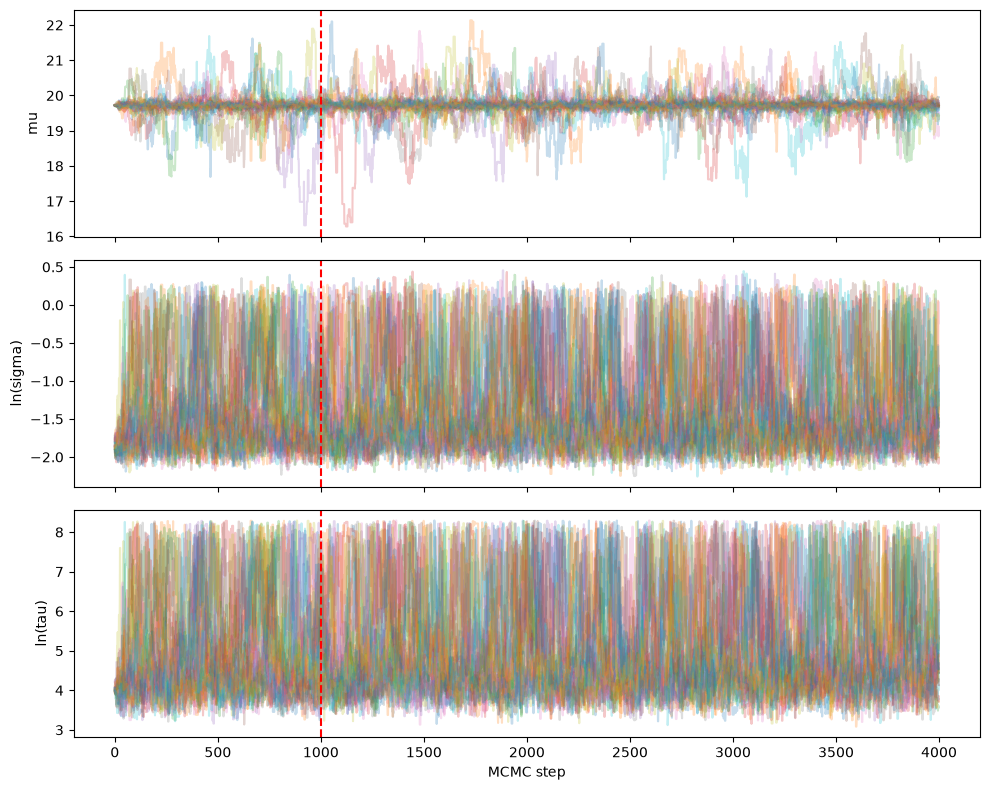

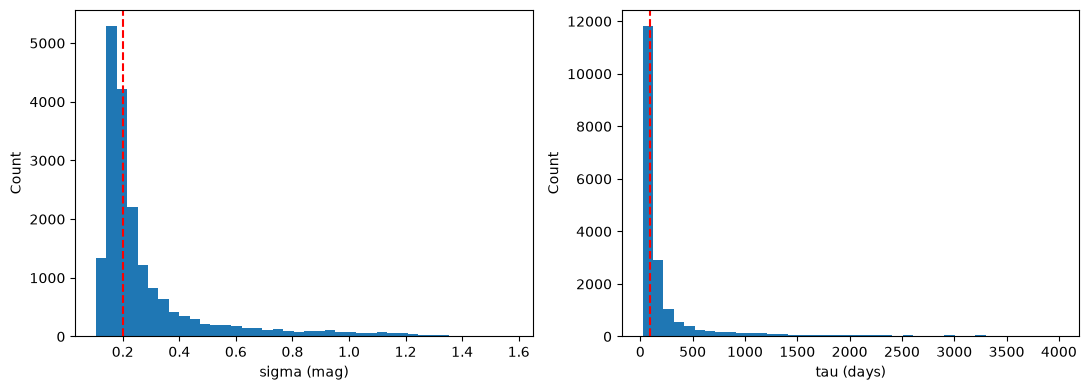

In [11]:
#2

bounds = [(None, None), (np.log(0.01), np.log(3)), (np.log(10), np.log(4000))]
starts = [[np.mean(y), np.log(0.1), np.log(100)], [np.mean(y), np.log(0.2), np.log(500)], [np.mean(y), np.log(0.5), np.log(1000)], [np.mean(y), np.log(0.05), np.log(2000)]]
results = [ minimize(lambda theta: -log_likelihood(theta, t, y, e), x0, method='L-BFGS-B', bounds=bounds) for x0 in starts]

for i, r in enumerate(results):
    print(f"Start {i+1}: success={r.success}, logL={-r.fun:.3f}, "
          f"sigma={np.exp(r.x[1]):.4f}, tau={np.exp(r.x[2]):.2f}")

valid = [r for r in results if r.success and np.isfinite(r.fun)]
if not valid:
    raise RuntimeError("No optimization converged successfully.")

best = min(valid, key=lambda r: r.fun)
mu_ml, ln_sigma_ml, ln_tau_ml = best.x

print("\nMaximum-likelihood fit:")
print(f"mu = {mu_ml:.4f} mag")
print(f"sigma = {np.exp(ln_sigma_ml):.4f} mag")
print(f"tau = {np.exp(ln_tau_ml):.2f} days")

ndim, nwalkers, nsteps = 3, 32, 4000
rng = np.random.default_rng(457)

p0 = best.x + rng.normal(0, [0.005, 0.05, 0.05], size=(nwalkers, ndim))

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior, args=(t, y, e))
sampler.run_mcmc(p0, nsteps, progress=True)

burnin = 1000
samples = sampler.get_chain(discard=burnin, thin=5, flat=True)

sigma_samples = np.exp(samples[:, 1])
tau_samples = np.exp(samples[:, 2])

s16, s50, s84 = np.percentile(sigma_samples, [16, 50, 84])
t16, t50, t84 = np.percentile(tau_samples, [16, 50, 84])

print("\nPosterior medians and 68% credible intervals:")
print(f"sigma = {s50:.4f} (+{s84-s50:.4f}/-{s50-s16:.4f}) mag")
print(f"tau = {t50:.2f} (+{t84-t50:.2f}/-{t50-t16:.2f}) days")
print(f"T/tau = {T/t50:.3f}")
print(f"Mean acceptance fraction = {np.mean(sampler.acceptance_fraction):.3f}")

try:
    autocorr = sampler.get_autocorr_time()
    print(f"Autocorrelation times: {autocorr}")
    print(f"Chain length / max autocorrelation time: "
          f"{nsteps/np.max(autocorr):.1f}")
except emcee.autocorr.AutocorrError as err:
    print("Autocorrelation estimate not reliable yet:", err)

chain = sampler.get_chain()
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for i, label in enumerate(["mu", "ln(sigma)", "ln(tau)"]):
    axes[i].plot(chain[:, :, i], alpha=0.25)
    axes[i].axvline(burnin, color='red', linestyle='--')
    axes[i].set_ylabel(label)

axes[-1].set_xlabel("MCMC step")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(sigma_samples, bins=40)
axes[0].axvline(s50, color='red', linestyle='--')
axes[0].set_xlabel("sigma (mag)")
axes[0].set_ylabel("Count")

axes[1].hist(tau_samples, bins=40)
axes[1].axvline(t50, color='red', linestyle='--')
axes[1].set_xlabel("tau (days)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

I used four different guesses and landed on the same one each time, indicating that it is stable across the initial conditions. 

Checked convergence with trace plots, acceptance fraction and autocorrelation time. 

There were several large gaps in the data, and only for 965 days, which may not be long enough to observe change. That makes it difficult to calculate tau. 

In [12]:
# 3

def log_likelihood_se(theta, t, y, e):
    mu, ln_sigma, ln_ell = theta
    sigma = np.exp(ln_sigma)
    ell = np.exp(ln_ell)
    dt = t[:, None] - t[None, :]
    C = sigma**2 * np.exp(-dt**2 / (2 * ell**2))
    C += np.diag(e**2)
    try:
        factor, lower = cho_factor(C, lower=True)
        residual = y - mu
        alpha = cho_solve((factor, lower), residual)
        logdet = 2 * np.sum(np.log(np.diag(factor)))

        return -0.5 * (residual @ alpha + logdet + len(y) * np.log(2*np.pi))
    except np.linalg.LinAlgError:
        return -np.inf

se_results = [minimize(lambda theta: -log_likelihood_se(theta, t, y, e), x0, method='L-BFGS-B', bounds=bounds) for x0 in starts]
valid_se = [r for r in se_results if r.success and np.isfinite(r.fun)]
best_se = min(valid_se, key=lambda r: r.fun)

logL_drw = -best.fun
logL_se = -best_se.fun

delta_logL = logL_drw - logL_se

print(f"DRW maximum logL: {logL_drw:.3f}")
print(f"Squared-exponential maximum logL: {logL_se:.3f}")
print(f"Delta logL (DRW - SE): {delta_logL:.3f}")
print(f"\nSE sigma: {np.exp(best_se.x[1]):.4f} mag")
print(f"SE ell: {np.exp(best_se.x[2]):.2f} days")

if delta_logL > 0:
    print("Exponential DRW kernel fits better.")
else:
    print("Squared-exponential kernel fits better.")

DRW maximum logL: 337.517
Squared-exponential maximum logL: 306.125
Delta logL (DRW - SE): 31.391

SE sigma: 0.1514 mag
SE ell: 10.00 days
Exponential DRW kernel fits better.


The DRW kernel produced a higher max-likelihood.

This suggests some irregular brightness fluctuations. 

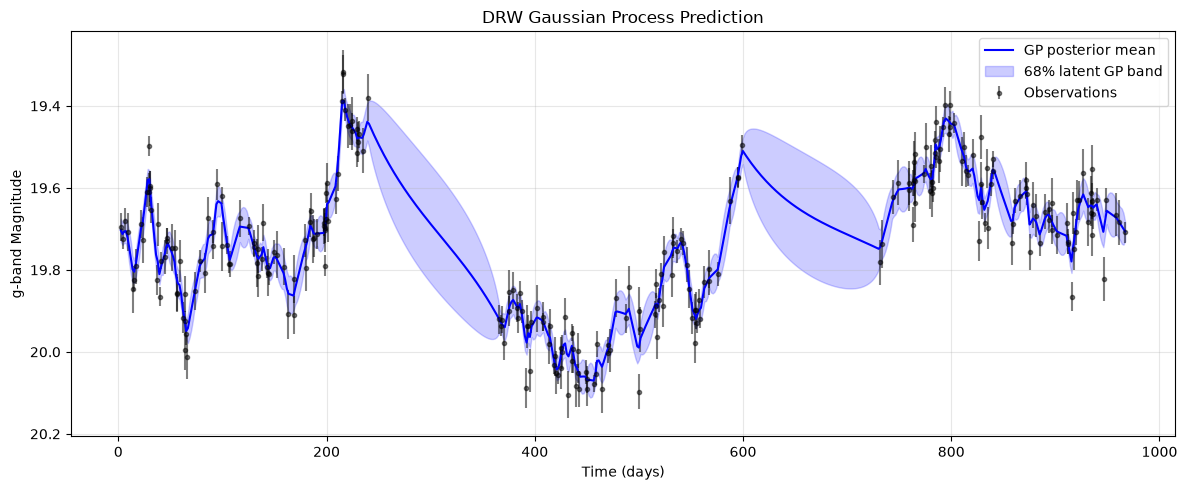

In [13]:
#4
mu, ln_sigma, ln_tau = best.x
sigma = np.exp(ln_sigma)
tau = np.exp(ln_tau)
t_pred = np.linspace(t.min(), t.max(), 600)

dt = np.abs(t[:, None] - t[None, :])
C = sigma**2 * np.exp(-dt / tau) + np.diag(e**2)

dt_cross = np.abs(t_pred[:, None] - t[None, :])
K_cross = sigma**2 * np.exp(-dt_cross / tau)

factor = cho_factor(C, lower=True)

alpha = cho_solve(factor, y - mu)
pred_mean = mu + K_cross @ alpha

V = cho_solve(factor, K_cross.T)
pred_var = sigma**2 - np.sum(K_cross * V.T, axis=1)
pred_std = np.sqrt(np.maximum(pred_var, 0))

plt.figure(figsize=(12, 5))
plt.errorbar(t, y, yerr=e, fmt='.', color='black', alpha=0.5, label='Observations')
plt.plot(t_pred, pred_mean, color='blue', label='GP posterior mean')
plt.fill_between(t_pred, pred_mean - pred_std, pred_mean + pred_std, color='blue', alpha=0.2, label='68% latent GP band')

plt.xlabel('Time (days)')
plt.ylabel('g-band Magnitude')
plt.title('DRW Gaussian Process Prediction')
plt.gca().invert_yaxis()
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This is the latent light curve. It matters because it has the measurement errors in the observed data points, while the band would not include these. 

Held-out blocks:
Days 73.5–103.5: 9 points
Days 435.3–465.3: 14 points
Days 567.7–597.7: 5 points
Days 785.0–815.0: 13 points

Total held-out observations: 41

DRW:
Inside 68% band: 31 / 41
Fraction inside: 0.756
R-squared: 0.884

Squared-exponential:
Inside 68% band: 26 / 41
Fraction inside: 0.634
R-squared: 0.815


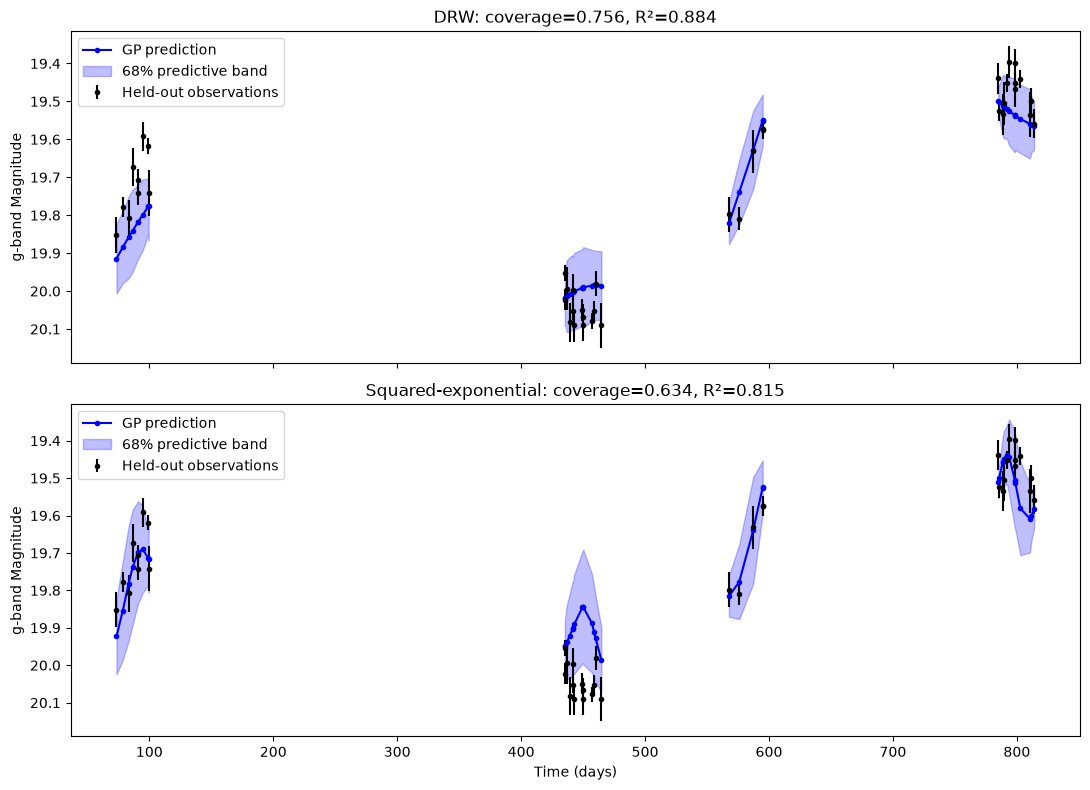

In [15]:
#5

rng = np.random.default_rng(457)
order = np.argsort(t)
ts = t[order]
season_id = np.cumsum(np.r_[0, np.diff(ts) > 45])
candidates = []
for season in np.unique(season_id):
    times = ts[season_id == season]
    for start in times:
        if start + 30 <= times.max():
            mask = (t >= start) & (t < start + 30)
            if mask.sum() >= 2:
                candidates.append((start, mask))
blocks = None
for attempt in range(10000):
    chosen = []
    for idx in rng.permutation(len(candidates)):
        start, mask = candidates[idx]
        if all(abs(start - old_start) >= 90
               for old_start, _ in chosen):
            chosen.append((start, mask))
        if len(chosen) == 4:
            blocks = chosen
            break
    if blocks is not None:
        break
if blocks is None:
    raise RuntimeError("Could not select four valid blocks.")
test_mask = np.zeros(len(t), dtype=bool)

for start, mask in blocks:
    test_mask |= mask
train_mask = ~test_mask
t_train, y_train, e_train = t[train_mask], y[train_mask], e[train_mask]
t_test, y_test, e_test = t[test_mask], y[test_mask], e[test_mask]

print("Held-out blocks:")
for start, mask in sorted(blocks):
    print(f"Days {start:.1f}–{start+30:.1f}: {mask.sum()} points")

print(f"\nTotal held-out observations: {len(y_test)}")
def fit_kernel(loglike):
    guesses = [[y_train.mean(), np.log(s), np.log(scale)] for s, scale in [(0.1, 100), (0.2, 500), (0.5, 1000), (0.05, 2000)]]
    results = [minimize(lambda theta: -loglike(theta, t_train, y_train, e_train), guess, method="L-BFGS-B", bounds=bounds) for guess in guesses]
    valid = [r for r in results if r.success and np.isfinite(r.fun)]
    if not valid:
        raise RuntimeError("Kernel fit failed.")
    return min(valid, key=lambda r: r.fun).x

def predict_test(theta, kernel):
    mu, ln_sigma, ln_scale = theta
    sigma = np.exp(ln_sigma)
    scale = np.exp(ln_scale)
    def covariance(a, b):
        dt = np.abs(a[:, None] - b[None, :])
        if kernel == "DRW":
            return sigma**2 * np.exp(-dt / scale)
        else:
            return sigma**2 * np.exp(-dt**2 / (2 * scale**2))

    C = covariance(t_train, t_train) + np.diag(e_train**2)
    K = covariance(t_test, t_train)
    factor = cho_factor(C, lower=True)

    alpha = cho_solve(factor, y_train - mu)
    pred = mu + K @ alpha

    V = cho_solve(factor, K.T)
    variance = sigma**2 - np.sum(K * V.T, axis=1) + e_test**2
    std = np.sqrt(np.maximum(variance, 0))
    return pred, std
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for ax, name, loglike in zip(axes, ["DRW", "Squared-exponential"], [log_likelihood, log_likelihood_se]): 
    theta = fit_kernel(loglike)
    pred, std = predict_test(theta, name)
    inside = np.abs(y_test - pred) <= std
    fraction = np.mean(inside)
    r2 = 1 - ( np.sum((y_test - pred)**2) / np.sum((y_test - y_train.mean())**2))
    print(f"\n{name}:")
    print(f"Inside 68% band: {inside.sum()} / {len(y_test)}")
    print(f"Fraction inside: {fraction:.3f}")
    print(f"R-squared: {r2:.3f}")

    ax.errorbar(t_test, y_test, yerr=e_test, fmt=".", color="black", label="Held-out observations" )

    for i, (start, _) in enumerate(sorted(blocks)):
        idx = np.where((t_test >= start) & (t_test < start + 30))[0]
        idx = idx[np.argsort(t_test[idx])]
        ax.plot(t_test[idx], pred[idx], "o-", color="blue", markersize=3, label="GP prediction" if i == 0 else None)
        ax.fill_between(t_test[idx], (pred - std)[idx], (pred + std)[idx], color="blue", alpha=0.25, label="68% predictive band" if i == 0 else None)

    ax.set_title(f"{name}: coverage={fraction:.3f}, R²={r2:.3f}")
    ax.set_ylabel("g-band Magnitude")
    ax.invert_yaxis()
    ax.legend()

axes[-1].set_xlabel("Time (days)")
plt.tight_layout()
plt.show()

Yes, the band follows the observations. 

**FINAL ANSWER:** *fill in the numbers above, here, in your own words*

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


In [ ]:
# Part 3: your work here

p-value: 0.01

Since quasars mimic periodic behavior, a p value of 0.01 reduces the chance of falsely identifying a periodic signal. 

Number of simulations: 2000
Observed maximum power: 0.3782
Simulations exceeding observed peak: 687
Empirical p-value: 0.34350
Astropy white-noise FAP: 3.53500e-25
Does not pass the p < 0.01 threshold.


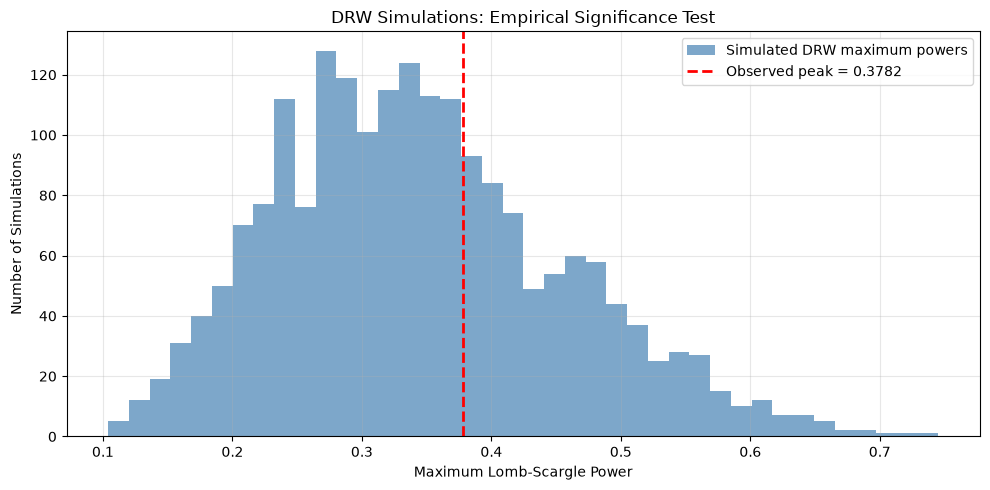

In [16]:
#2
rng = np.random.default_rng(457)
n_sim = 2000
mu, ln_sigma, ln_tau = best.x
sigma = np.exp(ln_sigma)
tau = np.exp(ln_tau)
dt = np.abs(t[:, None] - t[None, :])
K = sigma**2 * np.exp(-dt / tau)
L = np.linalg.cholesky(K + 1e-12 * np.eye(len(t)))

simulated_curves = np.empty((n_sim, len(t)))
max_powers = np.empty(n_sim)

for i in range(n_sim):
    z = rng.normal(size=len(t))
    drw = L @ z
    noise = rng.normal(0, e)
    y_sim = mu + drw + noise
    simulated_curves[i] = y_sim
    ls_sim = LombScargle(t, y_sim, e)
    sim_power = ls_sim.power(frequency)
    max_powers[i] = np.max(sim_power)

n_exceed = np.sum(max_powers >= peak_power)
p_empirical = n_exceed / n_sim

print(f"Number of simulations: {n_sim}")
print(f"Observed maximum power: {peak_power:.4f}")
print(f"Simulations exceeding observed peak: {n_exceed}")
print(f"Empirical p-value: {p_empirical:.5f}")
print(f"Astropy white-noise FAP: {fap:.5e}")

if p_empirical < 0.01:
    print("Passes the p < 0.01 threshold.")
else:
    print("Does not pass the p < 0.01 threshold.")

plt.figure(figsize=(10, 5))
plt.hist(max_powers, bins=40, color='steelblue', alpha=0.7, label='Simulated DRW maximum powers')
plt.axvline( peak_power, color='red', linestyle='--', linewidth=2, label=f'Observed peak = {peak_power:.4f}')
plt.xlabel('Maximum Lomb-Scargle Power')
plt.ylabel('Number of Simulations')
plt.title('DRW Simulations: Empirical Significance Test')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This p-value is much higher than mine, so it is not statistically signficant under the DRW model. 

Main sinusoid + DRW test
Best period: 32.37 days
Observed maximum delta chi-squared: 8.803
Empirical p-value: 0.67950

Sensitivity to tau:
tau = 53.12 days: p = 0.72350
tau = 373.27 days: p = 0.00000


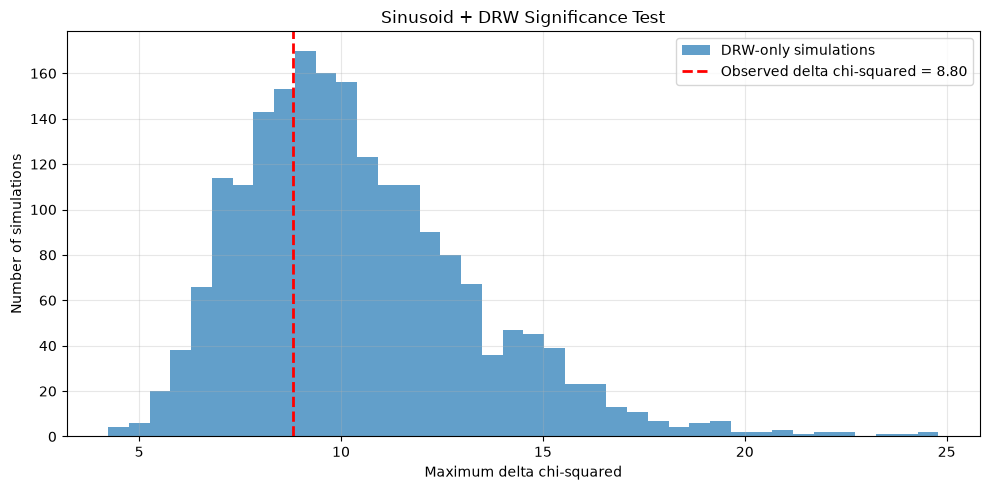


Decision:
Does not pass the preselected p < 0.01 threshold.


In [17]:
#3

from scipy.linalg import solve_triangular

mu_ml, ln_sigma_ml, ln_tau_ml = best.x
sigma_ml = np.exp(ln_sigma_ml)
tau_ml = np.exp(ln_tau_ml)

rng = np.random.default_rng(457)
n_sim = len(simulated_curves)


def scan_sinusoid(curves, tau):
    C = sigma_ml**2 * np.exp( -np.abs(t[:, None] - t[None, :]) / tau ) + np.diag(e**2)
    L = np.linalg.cholesky(C)

    q0 = solve_triangular( L, np.ones(len(t)), lower=True)
    q0 /= np.linalg.norm(q0)

    Y = np.atleast_2d(curves).T
    Z = solve_triangular(L, Y, lower=True)
    Z -= np.outer(q0, q0 @ Z)

    basis = []
    for f in frequency:
        X = np.column_stack([
            np.cos(2 * np.pi * f * t),
            np.sin(2 * np.pi * f * t)])
        Xw = solve_triangular(L, X, lower=True)
        Xw -= np.outer(q0, q0 @ Xw)
        Q, _ = np.linalg.qr(Xw)
        basis.append(Q.T)
    basis = np.vstack(basis)

    projections = basis @ Z
    delta = np.sum(projections.reshape(len(frequency), 2, -1)**2, axis=1)
    best_idx = np.argmax(delta, axis=0)
    return delta[best_idx, np.arange(Z.shape[1])], best_idx

observed_stat, observed_idx = scan_sinusoid(y, tau_ml)

sim_stats, _ = scan_sinusoid(simulated_curves, tau_ml)
observed_stat = observed_stat[0]
best_period_3 = 1 / frequency[observed_idx[0]]
p_value_3 = np.mean(sim_stats >= observed_stat)

print("Main sinusoid + DRW test")
print(f"Best period: {best_period_3:.2f} days")
print(f"Observed maximum delta chi-squared: {observed_stat:.3f}")
print(f"Empirical p-value: {p_value_3:.5f}")

tau_low = t16
tau_high = t84

print("\nSensitivity to tau:")

for tau_value in [tau_low, tau_high]:
    C = sigma_ml**2 * np.exp( -np.abs(t[:, None] - t[None, :]) / tau_value) + np.diag(e**2)
    L = np.linalg.cholesky(C)
    simulated = ( mu_ml + (L @ rng.normal(size=(len(t), n_sim))).T)
    obs_stat, _ = scan_sinusoid(y, tau_value)
    null_stats, _ = scan_sinusoid(simulated, tau_value)
    p = np.mean(null_stats >= obs_stat[0])
    print(f"tau = {tau_value:.2f} days: p = {p:.5f}")
plt.figure(figsize=(10, 5))
plt.hist( sim_stats, bins=40, alpha=0.7, label="DRW-only simulations")
plt.axvline( observed_stat, color="red", linestyle="--", linewidth=2, label=f"Observed delta chi-squared = {observed_stat:.2f}")

plt.xlabel("Maximum delta chi-squared")
plt.ylabel("Number of simulations")
plt.title("Sinusoid + DRW Significance Test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("\nDecision:")
if p_value_3 < 0.01:
    print("Passes the preselected p < 0.01 threshold.")
else:
    print("Does not pass the preselected p < 0.01 threshold.")

No, there is not significant evidence that there is a periodic signal under my rule.

I need a stronger signal that remains constant under DRW, with a longer observing time. They should not announce these results. 

**ANSWER (the decision rule first, then the verdict):**

*your answer goes here*

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


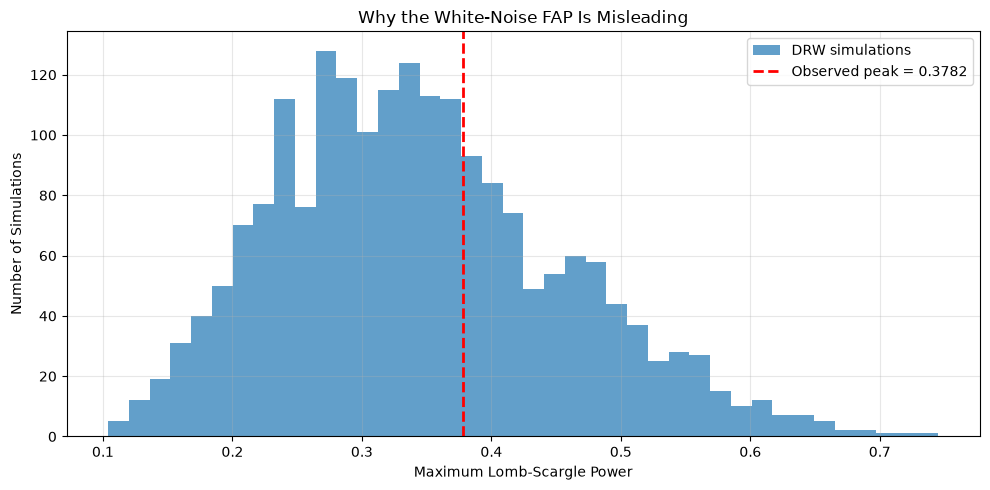

DRW empirical p-value: 0.3435
White-noise FAP: 3.535e-25


In [18]:
#1) In step 1, the ai solution assumes that the FAP indicates 
# that the periodicity is significant, however this the FAP takes into account
# white noise.
plt.figure(figsize=(10, 5))

plt.hist(max_powers, bins=40, alpha=0.7,
         label='DRW simulations')

plt.axvline(peak_power, color='red', linestyle='--',
            linewidth=2, label='Observed peak = 0.3782')

plt.xlabel('Maximum Lomb-Scargle Power')
plt.ylabel('Number of Simulations')
plt.title('Why the White-Noise FAP Is Misleading')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"DRW empirical p-value: {p_empirical:.4f}")
print(f"White-noise FAP: {fap:.3e}")


# The correct treatment is to simulate it with a DRW model. 

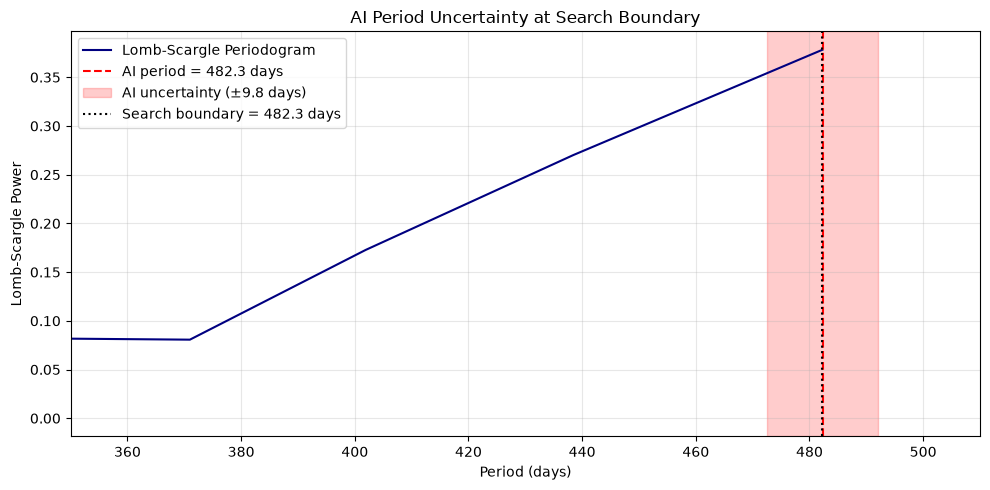

AI period: 482.3 ± 9.8 days
AI interval: 472.5 to 492.1 days
Maximum searched period: 482.28 days


In [20]:
#2) In step 1, the uncertainty calculation assumes that the white noise is independent. 
# In addition, the uncertainty goes over the period, which is not correct. 

P_ai = 482.3
P_err = 9.8
P_max = T / 2

plt.figure(figsize=(10, 5))

plt.plot(1 / frequency, power, color='navy',
         label='Lomb-Scargle Periodogram')
plt.axvline(P_ai, color='red', linestyle='--',
            label=f'AI period = {P_ai} days')
plt.axvspan(P_ai - P_err, P_ai + P_err,
            color='red', alpha=0.2,
            label='AI uncertainty (±9.8 days)')
plt.axvline(P_max, color='black', linestyle=':',
            label=f'Search boundary = {P_max:.1f} days')

plt.xlim(350, 510)
plt.xlabel('Period (days)')
plt.ylabel('Lomb-Scargle Power')
plt.title('AI Period Uncertainty at Search Boundary')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"AI period: {P_ai:.1f} ± {P_err:.1f} days")
print(f"AI interval: {P_ai-P_err:.1f} to {P_ai+P_err:.1f} days")
print(f"Maximum searched period: {P_max:.2f} days")

# The AI should have determined if statistical significance was there and then calculated 
# an uncertainty, assuming that white noise is correlated.

In [ ]:
#3) In step 2, the AI solution used a square exponential without justification
# 


# Part 4, Error 3: Compare GP kernels

models = ["Exponential DRW", "Squared-exponential"]
logL = [337.517, 306.125]
plt.figure(figsize=(8, 5))
plt.bar(models, logL, color=["steelblue", "orange"])
plt.ylabel("Maximum log-likelihood")
plt.title("Comparison of Gaussian Process Kernels")
plt.ylim(280, 345)

for i, value in enumerate(logL):
    plt.text(i, value + 1, f"{value:.3f}",
             ha="center")
plt.tight_layout()
plt.show()

print(f"Difference in log-likelihood: {logL[0] - logL[1]:.3f}")


# It should have compared the values against the DRW values and then decided if that assumption fits.

**REFEREE REPORT:**

*your report goes here*

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [21]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF19aanyknm: 711 g-band detections from the live API
ZTF19aanyknm: MJD 58561.5 to 61334.1 (7.6 yr); the last detection is MJD 61334.1; today is MJD 61348


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


Original observations: 711
Nightly averages: 443
Baseline: 2772.6 days

Best period: 447.19 days
Observed peak power: 0.3311

Fitted DRW parameters:
mu = 17.4848 mag
sigma = 0.0748 mag
tau = 243.75 days

Periodicity test:
Simulations: 2000
Exceedances: 1311
Empirical p-value: 0.65550
Significance threshold: 0.01
No significant evidence for periodicity.


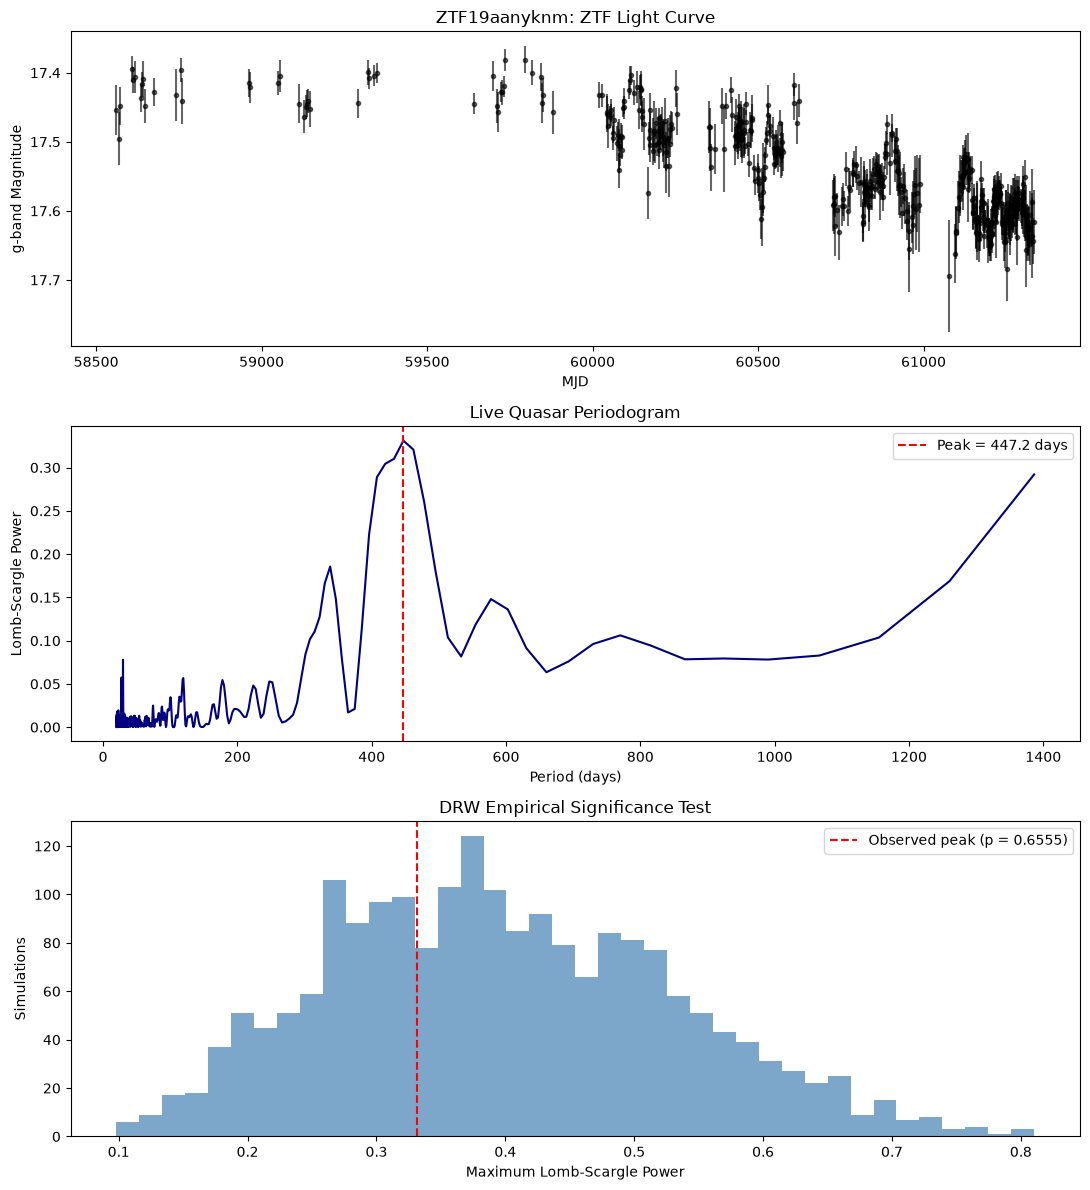

In [22]:
# Part 5: your work here
rng = np.random.default_rng(457)
n_sim = 2000
valid = np.isfinite(mjd) & np.isfinite(mag) & np.isfinite(merr) & (merr > 0)

times = mjd[valid]
mags = mag[valid]
errors = merr[valid]

nights = np.floor(times).astype(int)

t_live, y_live, e_live = [], [], []
for night in np.unique(nights):
    mask = nights == night
    w = 1 / errors[mask]**2
    t_live.append(np.average(times[mask], weights=w))
    y_live.append(np.average(mags[mask], weights=w))
    e_live.append(np.sqrt(1 / np.sum(w)))

t_live = np.array(t_live)
y_live = np.array(y_live)
e_live = np.array(e_live)

T_live = np.ptp(t_live)

print(f"Original observations: {len(times)}")
print(f"Nightly averages: {len(t_live)}")
print(f"Baseline: {T_live:.1f} days")

min_freq_live = 2 / T_live
max_freq_live = 1 / 20

frequency_live = np.arange( min_freq_live, max_freq_live, 1 / (5 * T_live))

ls_live = LombScargle(t_live, y_live, e_live)
power_live = ls_live.power(frequency_live)

peak_live = np.max(power_live)
best_period_live = 1 / frequency_live[np.argmax(power_live)]

print(f"\nBest period: {best_period_live:.2f} days")
print(f"Observed peak power: {peak_live:.4f}")

bounds_live = [ (None, None), (np.log(0.01), np.log(3)), (np.log(10), np.log(4000))]

starts_live = [
    [np.mean(y_live), np.log(0.1), np.log(100)],
    [np.mean(y_live), np.log(0.2), np.log(500)],
    [np.mean(y_live), np.log(0.5), np.log(1000)],
    [np.mean(y_live), np.log(0.1), np.log(2000)]]

results_live = [minimize( lambda theta: -log_likelihood( theta, t_live, y_live, e_live ), x0, method="L-BFGS-B", bounds=bounds_live ) for x0 in starts_live]

valid_fits = [
    r for r in results_live
    if r.success and np.isfinite(r.fun)]

if not valid_fits:
    raise RuntimeError("DRW optimization failed.")

best_live = min(valid_fits, key=lambda r: r.fun)

mu_live = best_live.x[0]
sigma_live = np.exp(best_live.x[1])
tau_live = np.exp(best_live.x[2])

print("\nFitted DRW parameters:")
print(f"mu = {mu_live:.4f} mag")
print(f"sigma = {sigma_live:.4f} mag")
print(f"tau = {tau_live:.2f} days")

n = len(t_live)
sim_curves = np.empty((n_sim, n))

sim_curves[:, 0] = (mu_live + sigma_live * rng.normal(size=n_sim))

for j in range(1, n):
    a = np.exp(-(t_live[j] - t_live[j-1]) / tau_live)
    sim_curves[:, j] = (mu_live + a * (sim_curves[:, j-1] - mu_live) + sigma_live * np.sqrt(1 - a**2) * rng.normal(size=n_sim))

sim_curves += rng.normal( size=(n_sim, n)) * e_live[None, :]
max_powers_live = np.empty(n_sim)

for i in range(n_sim):
    ls_sim = LombScargle(t_live, sim_curves[i], e_live)
    max_powers_live[i] = np.max( ls_sim.power(frequency_live))

n_exceed_live = np.sum(max_powers_live >= peak_live)
p_live = n_exceed_live / n_sim

print("\nPeriodicity test:")
print(f"Simulations: {n_sim}")
print(f"Exceedances: {n_exceed_live}")
print(f"Empirical p-value: {p_live:.5f}")
print("Significance threshold: 0.01")

if p_live < 0.01:
    print("Passes the significance threshold.")
else:
    print("No significant evidence for periodicity.")

fig, axes = plt.subplots(3, 1, figsize=(11, 12))

axes[0].errorbar( t_live, y_live, yerr=e_live, fmt=".", color="black", alpha=0.6)
axes[0].invert_yaxis()
axes[0].set_xlabel("MJD")
axes[0].set_ylabel("g-band Magnitude")
axes[0].set_title(f"{OID}: ZTF Light Curve")

axes[1].plot(1 / frequency_live, power_live, color="navy")
axes[1].axvline( best_period_live,  color="red", linestyle="--", label=f"Peak = {best_period_live:.1f} days")
axes[1].set_xlabel("Period (days)")
axes[1].set_ylabel("Lomb-Scargle Power")
axes[1].set_title("Live Quasar Periodogram")
axes[1].legend()

axes[2].hist(max_powers_live, bins=40, color="steelblue", alpha=0.7)
axes[2].axvline( peak_live, color="red", linestyle="--", label=f"Observed peak (p = {p_live:.4f})")
axes[2].set_xlabel("Maximum Lomb-Scargle Power")
axes[2].set_ylabel("Simulations")
axes[2].set_title("DRW Empirical Significance Test")
axes[2].legend()

plt.tight_layout()
plt.show()

**ANSWER (the criterion first, then the result):**

I will run with the value I chose earlier as 0.01. 

With another week, I would investigate the uncertainty in the DRW parameters and see if anything changes.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

I used ChatGPT.

Part 1
Chat gave me the code for the first plot as it was faster. 

Requested code for the second part and the plotting. 

Part 2:
1) Asked for code for this.

I asked for boilerplate code for the rest of this section as well.

Part 3:
I asked for help getting a p-value to use. I asked for boilerplate code for this section, and asked it to explain the results of each section. 

Part 4:
Asked chat for the plot to show the error for the first one I found.

2) Checked the error with chat, asked for more explaination, requested code. 

3) Checked the error with chat, asked for more explaination, requested code.


Part 5)
I asked questions about this one. I requested code for this as well. 

Part 6:
I asked for the boilerplate code for part 6.
**REFLECTION:**

If I did not check the step 1, specifically the periods, then it would have thrown off my answers for the rest of the lab. 

**VERIFICATION PLAN:**

I used a synthetic DRW light curve with a known sigma and tau.

DRW parameter recovery
Optimization successful: True
True sigma: 0.1600
Recovered sigma (MLE): 0.1517
True tau: 60.00
Recovered tau (MLE): 71.54


100%|██████████████████████████████████████| 2000/2000 [01:50<00:00, 18.13it/s]



68% credible interval checks
Sigma interval: 0.1523 to 0.4960
True sigma inside: True
Tau interval: 71.25 to 819.73
True tau inside: False

Periodicity verification
Planted period: 120.00 days
Recovered peak period: 120.57 days
No-sinusoid p-value: 0.5980
Planted-sinusoid p-value: 0.0030
Null test detects periodicity: False
Injected signal detected: True


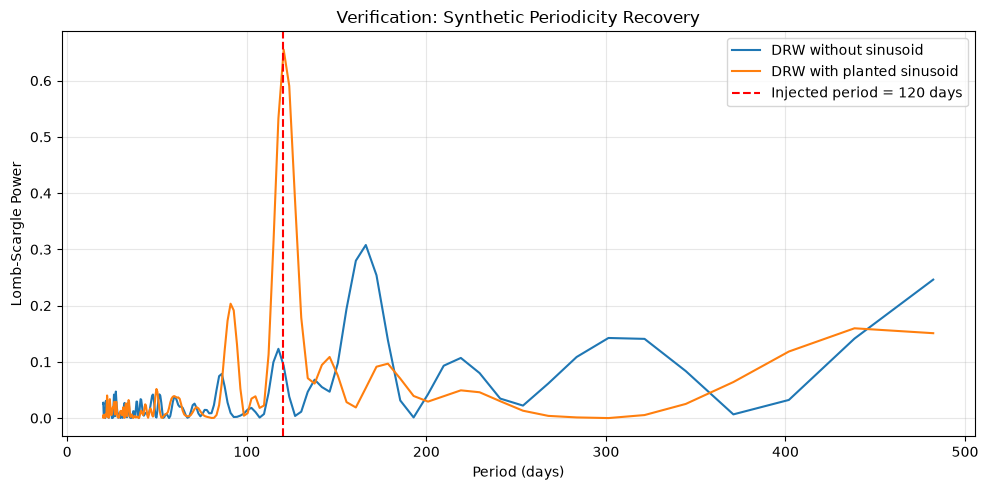

In [23]:
# Part 6, Question 3: Synthetic verification test

rng = np.random.default_rng(457)

# Known parameters
true_mu = 19.72
true_sigma = 0.16
true_tau = 60.0

# Planted sinusoidal signal
true_period = 120.0
true_amplitude = 0.35

# Generate synthetic DRW
dt = np.abs(t[:, None] - t[None, :])
K = true_sigma**2 * np.exp(-dt / true_tau)
L = np.linalg.cholesky(K + 1e-12 * np.eye(len(t)))

drw = L @ rng.normal(size=len(t))
noise = rng.normal(0, e)

# Without and with a sinusoid
y_null = true_mu + drw + noise

y_signal = y_null + true_amplitude * np.sin(
    2 * np.pi * t / true_period
)

# Fit the DRW-only synthetic data
bounds_test = [
    (None, None),
    (np.log(0.01), np.log(3)),
    (np.log(10), np.log(4000))
]

result = minimize(
    lambda theta: -log_likelihood(theta, t, y_null, e),
    [np.mean(y_null), np.log(0.16), np.log(60)],
    method="L-BFGS-B",
    bounds=bounds_test
)

print("DRW parameter recovery")
print(f"Optimization successful: {result.success}")
print(f"True sigma: {true_sigma:.4f}")
print(f"Recovered sigma (MLE): {np.exp(result.x[1]):.4f}")
print(f"True tau: {true_tau:.2f}")
print(f"Recovered tau (MLE): {np.exp(result.x[2]):.2f}")

# MCMC for 68% credible intervals
ndim, nwalkers = 3, 32

p0 = result.x + rng.normal(
    0, [0.005, 0.03, 0.03],
    size=(nwalkers, ndim)
)

sampler_test = emcee.EnsembleSampler(
    nwalkers, ndim, log_posterior,
    args=(t, y_null, e)
)

sampler_test.run_mcmc(p0, 2000, progress=True)

samples_test = sampler_test.get_chain(
    discard=500, thin=5, flat=True
)

sigma_ci = np.percentile(
    np.exp(samples_test[:, 1]), [16, 50, 84]
)

tau_ci = np.percentile(
    np.exp(samples_test[:, 2]), [16, 50, 84]
)

print("\n68% credible interval checks")
print(f"Sigma interval: {sigma_ci[0]:.4f} to {sigma_ci[2]:.4f}")
print(f"True sigma inside: {sigma_ci[0] <= true_sigma <= sigma_ci[2]}")

print(f"Tau interval: {tau_ci[0]:.2f} to {tau_ci[2]:.2f}")
print(f"True tau inside: {tau_ci[0] <= true_tau <= tau_ci[2]}")

# Periodograms with and without a signal
power_null = LombScargle(t, y_null, e).power(frequency)
power_signal = LombScargle(t, y_signal, e).power(frequency)

# Simulated DRW null distribution
n_verify = 1000
max_verify = np.empty(n_verify)

for i in range(n_verify):
    simulated = (
        true_mu
        + L @ rng.normal(size=len(t))
        + rng.normal(0, e)
    )

    max_verify[i] = np.max(
        LombScargle(t, simulated, e).power(frequency)
    )

p_null = np.mean(max_verify >= np.max(power_null))
p_signal = np.mean(max_verify >= np.max(power_signal))

period_recovered = 1 / frequency[np.argmax(power_signal)]

print("\nPeriodicity verification")
print(f"Planted period: {true_period:.2f} days")
print(f"Recovered peak period: {period_recovered:.2f} days")
print(f"No-sinusoid p-value: {p_null:.4f}")
print(f"Planted-sinusoid p-value: {p_signal:.4f}")

print(f"Null test detects periodicity: {p_null < 0.01}")
print(f"Injected signal detected: {p_signal < 0.01}")

# Plot verification results
plt.figure(figsize=(10, 5))

plt.plot(1 / frequency, power_null,
         label="DRW without sinusoid")

plt.plot(1 / frequency, power_signal,
         label="DRW with planted sinusoid")

plt.axvline(true_period, color="red",
            linestyle="--",
            label="Injected period = 120 days")

plt.xlabel("Period (days)")
plt.ylabel("Lomb-Scargle Power")
plt.title("Verification: Synthetic Periodicity Recovery")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# These results demonstrate that the methods I used were accurate.